In [23]:
from pathlib import Path
import duckdb

root = Path.cwd().parent
RAW = root / "data" / "raw"
PROC = root / "data" / "processed"
PROC.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
print(RAW, list(RAW.iterdir()))

c:\Users\simpl\projects\ecommerce-recommender\data\raw [WindowsPath('c:/Users/simpl/projects/ecommerce-recommender/data/raw/articles.csv'), WindowsPath('c:/Users/simpl/projects/ecommerce-recommender/data/raw/customers.csv'), WindowsPath('c:/Users/simpl/projects/ecommerce-recommender/data/raw/transactions_train.csv')]


In [25]:
for name in ["transactions_train", "customers", "articles"]:
    con.execute(f"""
        COPY (SELECT * FROM read_csv_auto('{(RAW / f"{name}.csv").as_posix()}'))
        TO '{(PROC / f"{name}.parquet").as_posix()}' (FORMAT PARQUET)
    """)
    print("done:", name)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

done: transactions_train


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

done: customers
done: articles


In [26]:
T = f"'{(PROC / 'transactions_train.parquet').as_posix()}'"
con.sql(f"SELECT * FROM {T} LIMIT 5").df()

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687004,0.016932,2


In [8]:
con.sql(f"""
    select count(*) as n_transactions,
           count(distinct customer_id) as n_customers,
           count (distinct article_id) as n_articles,
           count (distinct sales_channel_id) as n_saleschannels
           from {T}
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_transactions,n_customers,n_articles,n_saleschannels
0,31788324,1362281,104547,2


In [10]:
con.sql(f"""
        select min(t_dat) as first_date,
               max(t_dat) as last_date,
               date_diff('day', min(t_dat), max(t_dat)) as _days
        from {T}
""").df()

,first_date,last_date,_days
0,2018-09-20,2020-09-22,733


In [12]:
weekly = con.sql(f"""
         select date_trunc('week', t_dat) as week,
                count(*)                    as n_tx,
                count(distinct customer_id) as n_customers
        from {T}
        group by 1
        order by 1
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [13]:
print("Average transactions per week:", round(weekly["n_tx"].mean()))
weekly.tail(3)

Average transactions per week: 299890


,week,n_tx,n_customers
103,2020-09-07,273575,76528
104,2020-09-14,231309,66499
105,2020-09-21,64996,20233


In [15]:
con.sql(f"""
       select count(*)    as n_tx_last_7_days,
              count(distinct customer_id) as n_customers_last_7_days
       from {T}
       where t_dat > (select max(t_dat) from {T}) - interval 7 day
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_tx_last_7_days,n_customers_last_7_days
0,240311,68984


Plotting weekly trend

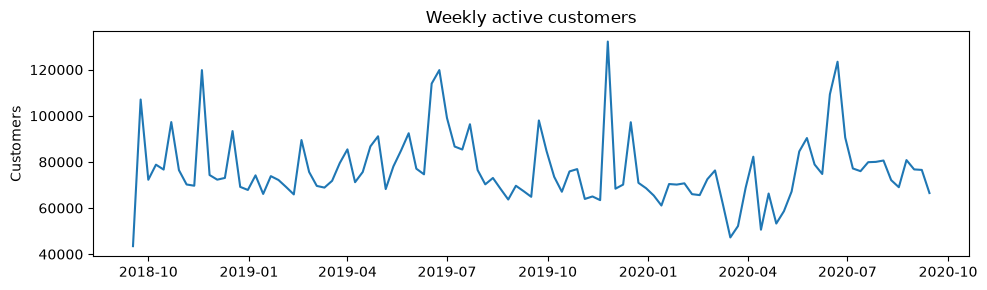

In [17]:
import matplotlib.pyplot as plt

w = weekly.iloc[:-1]  #dropping the partial final week
fig, ax = plt.subplots(figsize=(10,3))
ax.plot(w["week"], w["n_customers"])
ax.set_title("Weekly active customers")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()

In [28]:
C = f"'{(PROC / 'customers.parquet').as_posix()}'"
A = f"'{(PROC / 'articles.parquet').as_posix()}'"


What share of registered customers ever brought?

In [30]:
cov = con.sql(f"""
    WITH buyers AS (SELECT DISTINCT customer_id FROM {T})
    SELECT (SELECT count(*) FROM {C}) AS customers_registered,
           (SELECT count(*) FROM {C} WHERE customer_id IN (SELECT customer_id FROM buyers)) AS customers_who_bought
""").df()

cov["pct_bought"] = 100 * cov["customers_who_bought"] / cov["customers_registered"]
cov

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customers_registered,customers_who_bought,pct_bought
0,1371980,1362281,99.293065


The Price Column

In [32]:
con.sql(f"""
      select min(price) as min_price,
      approx_quantile(price, 0.5)  as median_price,
      avg(price) as avg_price,
      max(price) as max_price
      from {T}
""").df()

,min_price,median_price,avg_price,max_price
0,0.000017,0.025406,0.027829,0.591525


The Business Problem: How many times does each customer come back?

In [33]:
trips = con.sql(f""" 
        with per_customer as (
            select customer_id, count(distinct t_dat) as n_trips
             from {T} 
             group by 1
    )
    select case when n_trips  = 1 then '1 trip'
                when n_trips = 2 then '2 trips'
                when n_trips <= 5 then '3-5 trips'
                when n_trips <= 10 then '6-10 trips'
                else '11+ trips' end as bucket,
            count(*) as customers
    from per_customer
    group by 1
    order by min(n_trips)
""").df()


trips["pct"] = (100 * trips["customers"] / trips["customers"].sum()).round(1)
trips

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,bucket,customers,pct
0,1 trip,447973,32.9
1,2 trips,183116,13.4
2,3-5 trips,262425,19.3
3,6-10 trips,203782,15.0
4,11+ trips,264985,19.5


Online Vs In-Store Purchase Analysis

In [34]:
con.sql(f"""
    SELECT sales_channel_id,
           count(*) AS n_tx,
           round(100.0 * count(*) / sum(count(*)) OVER (), 1) AS pct
    FROM {T}
    GROUP BY 1
    ORDER BY 1
""").df()

,sales_channel_id,n_tx,pct
0,1,9408462,29.6
1,2,22379862,70.4


Observations:
- 31.8M transactions, 1.36M customers, 104.5K articles, 20 Sep 2018 – 22 Sep 2020 (733 days)
- ~300K transactions per week; strong seasonality with peaks in Nov–Dec and September
- 99.3% of registered customers bought at least once (9,699 never did)
- 32.9% of customers made only one shopping trip; X% among customers with 6+ months of history (corrected for right-censoring)
- 19.5% of customers made 11+ trips: a loyal core
- 70.4% of transactions are online, 29.6% in-store
- Prices are scaled by H&M (median 0.025, max 0.59), not real currency; X% are below 0.001
- Test week (last 7 days): X customers

Near Zero Prices

In [36]:
con.sql(f"""
     select count(*) filter (where price < 0.001) as n_below_0_001,
     round(100.0 * count(*) filter (where price < 0.001) / count(*), 3) as pct_below_0_001
     from {T}
""").df()

,n_below_0_001,pct_below_0_001
0,14288,0.045


Censoring-corrected one-trip rate

In [37]:
con.sql(f"""
    WITH per_customer AS (
        SELECT customer_id,
               min(t_dat)            AS first_day,
               count(DISTINCT t_dat) AS n_trips
        FROM {T}
        GROUP BY 1
    )
    SELECT count(*) AS customers_with_6m_history,
           round(100.0 * avg(CASE WHEN n_trips = 1 THEN 1 ELSE 0 END), 1) AS pct_one_trip
    FROM per_customer
    WHERE first_day <= (SELECT max(t_dat) FROM {T}) - INTERVAL 180 DAY
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customers_with_6m_history,pct_one_trip
0,1189917,27.8
